# DeepWeeds - KNN, Softmax, CNN et modèles préentraînés

**Classes :** Chinee apple, Lantana, Snake weed.

| Groupe | Modèles | Images | Train | Validation | Test |
|---|---|---:|---:|---:|---:|
| Petit échantillon | Pixels + KNN, Softmax pixels, CNN | 900 | 540 | 180 | 180 |
| Échantillon complet | CNN, Softmax pixels, EfficientNetB0 et DINOv2 + KNN/Softmax, ResNet50 gelé et fine-tuné, InceptionV3 | 3 000 | 1 800 | 600 | 600 |

Le CNN est testé sur les deux volumes. Les comparaisons **au sein de chaque groupe** utilisent exactement les mêmes images de validation et de test. Les résolutions, préentraînements et méthodes restent différents.

## 1. Imports

In [1]:
%pip install importlib-resources

import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tensorflow.keras import layers, models

for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

class_names = ['Chinee apple', 'Lantana', 'Snake weed']

tf.keras.utils.set_random_seed(42)
validation_rows = []
test_predictions = []
histories = []

## 2. Données

In [2]:
dataset, info = tfds.load('deep_weeds', split='train', as_supervised=True,
                         with_info=True, shuffle_files=False)

counts = {0: 0, 1: 0, 7: 0}
label_map = {0: 0, 1: 1, 7: 2}
images, labels = [], []

for image, label in tfds.as_numpy(dataset):
    label = int(label)
    if label in counts and counts[label] < 1000:
        images.append(image)
        labels.append(label_map[label])
        counts[label] += 1
    if min(counts.values()) == 1000:
        break

images = np.array(images)
y = np.array(labels)
assert list(counts.values()) == [1000, 1000, 1000]
print('Images:', images.shape, '| Labels:', y.shape)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/deep_weeds/incomplete.HBRPOI_3.0.0/deep_weeds-train.tfrecord-[0-9][0-9][0-…

Dataset deep_weeds downloaded and prepared to /root/tensorflow_datasets/deep_weeds/3.0.0. Subsequent calls will reuse this data.
Images: (3000, 256, 256, 3) | Labels: (3000,)


### Splits communs

Le sous-échantillon de 900 images garde les **300 premières images de chaque classe**.

In [3]:
# Groupe de 3 000 images : mêmes indices pour tous les modèles.
indices = np.arange(len(y))
train_val_idx, test_idx = train_test_split(
    indices, test_size=0.2, random_state=42, stratify=y)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.25, random_state=42, stratify=y[train_val_idx])
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

# Groupe de 900 images : mêmes images et splits que le KNN brut.
mask = np.zeros(len(y), dtype=bool)
for label in range(3):
    mask[np.where(y == label)[0][:300]] = True
small_idx = np.where(mask)[0]
small_temp_idx, small_test_idx = train_test_split(
    small_idx, test_size=0.2, random_state=42, stratify=y[small_idx])
small_train_idx, small_val_idx = train_test_split(
    small_temp_idx, test_size=0.25, random_state=42, stratify=y[small_temp_idx])

rows = []
for group, training, validation, testing in [
    [900, small_train_idx, small_val_idx, small_test_idx],
    [3000, train_idx, val_idx, test_idx]
]:
    assert not (set(training) & set(validation) or set(training) & set(testing)
                or set(validation) & set(testing))
    for split, selected in [('Train', training), ('Validation', validation), ('Test', testing)]:
        rows.append([group, split, len(selected), *np.bincount(y[selected], minlength=3)])

distribution = pd.DataFrame(rows, columns=['Groupe', 'Split', 'Images', *class_names])
display(Markdown(distribution.to_markdown(index=False)))

|   Groupe | Split      |   Images |   Chinee apple |   Lantana |   Snake weed |
|---------:|:-----------|---------:|---------------:|----------:|-------------:|
|      900 | Train      |      540 |            180 |       180 |          180 |
|      900 | Validation |      180 |             60 |        60 |           60 |
|      900 | Test       |      180 |             60 |        60 |           60 |
|     3000 | Train      |     1800 |            600 |       600 |          600 |
|     3000 | Validation |      600 |            200 |       200 |          200 |
|     3000 | Test       |      600 |            200 |       200 |          200 |

## 3. Pixels + KNN - 900 images

Pixels 32 × 32 dans [0, 1]. Ces mêmes pixels seront utilisés par le CNN.

In [4]:
pixels32 = tf.image.resize(images, (32, 32)).numpy() / 255.0
raw_features = pixels32.reshape(len(y), -1)

scores = []
for k in [1, 3, 5, 7, 9]:
    for metric in ['euclidean', 'manhattan']:
        model = KNeighborsClassifier(n_neighbors=k, metric=metric)
        model.fit(raw_features[small_train_idx], y[small_train_idx])
        score = accuracy_score(y[small_val_idx], model.predict(raw_features[small_val_idx]))
        scores.append([k, metric, score * 100])

validation_raw = pd.DataFrame(scores, columns=['k', 'Distance', 'Validation (%)'])
display(Markdown(validation_raw.pivot(index='k', columns='Distance',
                                    values='Validation (%)').to_markdown(floatfmt='.2f')))
best_raw = validation_raw.loc[validation_raw['Validation (%)'].idxmax()]
knn_raw = KNeighborsClassifier(n_neighbors=int(best_raw['k']), metric=best_raw['Distance'])
knn_raw.fit(raw_features[small_train_idx], y[small_train_idx])

validation_rows.append(['Pixels + KNN', 900, 32, best_raw['Validation (%)']])
test_predictions.append(['Pixels + KNN', y[small_test_idx], knn_raw.predict(raw_features[small_test_idx])])

|   k |   euclidean |   manhattan |
|----:|------------:|------------:|
|   1 |       39.44 |       41.67 |
|   3 |       41.11 |       39.44 |
|   5 |       38.89 |       38.89 |
|   7 |       39.44 |       38.33 |
|   9 |       37.78 |       38.89 |

## 4. EfficientNetB0 + KNN - 3 000 images

Extracteur gelé, pixels dans [0, 255], moyenne globale → **1 280 features**. Distance euclidienne et vote pondéré.

In [5]:
from tensorflow.keras.applications import EfficientNetB0

effnet = EfficientNetB0(weights='imagenet', include_top=False, pooling='avg')
effnet.trainable = False

eff_features = []
for start in range(0, len(images), 32):
    batch = tf.image.resize(images[start:start + 32], (224, 224))
    eff_features.append(effnet.predict(batch, verbose=0))
eff_features = np.concatenate(eff_features)
print('Features:', eff_features.shape)

del effnet, batch
tf.keras.backend.clear_session()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Features: (3000, 1280)


In [6]:
scores = []
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean', weights='distance')
    knn.fit(eff_features[train_idx], y_train)
    accuracy = accuracy_score(y_val, knn.predict(eff_features[val_idx]))
    scores.append([k, accuracy * 100])

validation_eff = pd.DataFrame(scores, columns=['k', 'Validation (%)'])
display(Markdown(validation_eff.to_markdown(index=False, floatfmt='.2f')))
best_eff = validation_eff.loc[validation_eff['Validation (%)'].idxmax()]
print('Best k:', int(best_eff['k']))

knn_eff = KNeighborsClassifier(n_neighbors=int(best_eff['k']), metric='euclidean', weights='distance')
knn_eff.fit(eff_features[train_idx], y_train)
validation_rows.append(['EfficientNetB0 + KNN', 3000, 224, best_eff['Validation (%)']])
test_predictions.append(['EfficientNetB0 + KNN', y_test, knn_eff.predict(eff_features[test_idx])])

|     k |   Validation (%) |
|------:|-----------------:|
|  1.00 |            82.17 |
|  3.00 |            83.33 |
|  5.00 |            84.00 |
|  7.00 |            83.17 |
|  9.00 |            83.17 |
| 11.00 |            83.33 |
| 15.00 |            81.67 |
| 21.00 |            81.17 |

Best k: 5


## 5. CNN simple - 900 puis 3 000 images

Même architecture et recette d’entraînement pour les deux volumes : augmentation forte, Adam cosinus 2e-3, batch 32, 300 époques. Meilleur checkpoint sur `val_loss`. TTA choisie uniquement sur la validation.

Le CNN utilise maintenant le redimensionnement bilinéaire du KNN, sans arrondi supplémentaire, pour partager exactement les mêmes pixels 32 × 32.

In [7]:
for name, training, validation, testing in [
    ['CNN (900)', small_train_idx, small_val_idx, small_test_idx],
    ['CNN (3000)', train_idx, val_idx, test_idx]
]:
    tf.keras.utils.set_random_seed(2)
    model = models.Sequential([
        layers.Input((32, 32, 3)),
        layers.RandomFlip('horizontal_and_vertical'),
        layers.RandomRotation(0.25),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.10, 0.10),
        layers.RandomContrast(0.20),
        layers.RandomBrightness(0.15, value_range=(0.0, 1.0)),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(3, activation='softmax')
    ])
    learning_rate = tf.keras.optimizers.schedules.CosineDecay(
        2e-3, decay_steps=int(np.ceil(len(training) / 32)) * 300, alpha=0.05)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    checkpoint_path = f'cnn_{len(training)}_best.weights.h5'
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        checkpoint_path, monitor='val_loss', save_best_only=True, save_weights_only=True)
    history = model.fit(pixels32[training], y[training],
                        validation_data=(pixels32[validation], y[validation]),
                        epochs=300, batch_size=32, callbacks=[checkpoint], verbose=2)
    model.load_weights(checkpoint_path)
    histories.append([name, history.history])

    normal = model.predict(pixels32[validation], verbose=0)
    tta = []
    for k in range(4):
        rotated = np.rot90(pixels32[validation], k, axes=(1, 2))
        tta.append(model.predict(rotated, verbose=0))
        tta.append(model.predict(rotated[:, :, ::-1], verbose=0))
    augmented = np.mean(tta, axis=0)
    normal_score = accuracy_score(y[validation], normal.argmax(1)) * 100
    tta_score = accuracy_score(y[validation], augmented.argmax(1)) * 100
    table = pd.DataFrame([['Sans TTA', normal_score], ['Avec TTA', tta_score]],
                         columns=['Prédiction', 'Validation (%)'])
    display(Markdown(f'### {name}'))
    display(Markdown(table.to_markdown(index=False, floatfmt='.2f')))
    use_tta = tta_score > normal_score
    selected_name = name + (' + TTA' if use_tta else '')
    validation_rows.append([selected_name, len(training) + len(validation) + len(testing),
                            32, max(normal_score, tta_score)])

    # Préparer les prédictions test ; les scores seront affichés à la fin.
    if use_tta:
        tta = []
        for k in range(4):
            rotated = np.rot90(pixels32[testing], k, axes=(1, 2))
            tta.append(model.predict(rotated, verbose=0))
            tta.append(model.predict(rotated[:, :, ::-1], verbose=0))
        probabilities = np.mean(tta, axis=0)
    else:
        probabilities = model.predict(pixels32[testing], verbose=0)
    test_predictions.append([selected_name, y[testing], probabilities.argmax(1)])
    del model
    tf.keras.backend.clear_session()
    gc.collect()

Epoch 1/300
17/17 - 9s - 507ms/step - accuracy: 0.3574 - loss: 1.0997 - val_accuracy: 0.4111 - val_loss: 1.0656
Epoch 2/300
17/17 - 0s - 13ms/step - accuracy: 0.4352 - loss: 1.0468 - val_accuracy: 0.3444 - val_loss: 1.1865
Epoch 3/300
17/17 - 0s - 12ms/step - accuracy: 0.4833 - loss: 0.9997 - val_accuracy: 0.3611 - val_loss: 1.1989
Epoch 4/300
17/17 - 0s - 13ms/step - accuracy: 0.5074 - loss: 0.9550 - val_accuracy: 0.3833 - val_loss: 1.1936
Epoch 5/300
17/17 - 0s - 15ms/step - accuracy: 0.4815 - loss: 0.9691 - val_accuracy: 0.4833 - val_loss: 0.9976
Epoch 6/300
17/17 - 0s - 14ms/step - accuracy: 0.5093 - loss: 0.9595 - val_accuracy: 0.3889 - val_loss: 1.2364
Epoch 7/300
17/17 - 0s - 13ms/step - accuracy: 0.4741 - loss: 0.9559 - val_accuracy: 0.4000 - val_loss: 1.2145
Epoch 8/300
17/17 - 0s - 16ms/step - accuracy: 0.5148 - loss: 0.9585 - val_accuracy: 0.4722 - val_loss: 0.9896
Epoch 9/300
17/17 - 0s - 14ms/step - accuracy: 0.5352 - loss: 0.9380 - val_accuracy: 0.4056 - val_loss: 1.1786


### CNN (900)

| Prédiction   |   Validation (%) |
|:-------------|-----------------:|
| Sans TTA     |            67.78 |
| Avec TTA     |            67.22 |

Epoch 1/300
57/57 - 3s - 50ms/step - accuracy: 0.3733 - loss: 1.0907 - val_accuracy: 0.3733 - val_loss: 1.1225
Epoch 2/300
57/57 - 1s - 10ms/step - accuracy: 0.4267 - loss: 1.0504 - val_accuracy: 0.4867 - val_loss: 1.0095
Epoch 3/300
57/57 - 1s - 10ms/step - accuracy: 0.4161 - loss: 1.0814 - val_accuracy: 0.3633 - val_loss: 1.1341
Epoch 4/300
57/57 - 1s - 10ms/step - accuracy: 0.4833 - loss: 1.0131 - val_accuracy: 0.5000 - val_loss: 1.0127
Epoch 5/300
57/57 - 1s - 14ms/step - accuracy: 0.4772 - loss: 1.0024 - val_accuracy: 0.4783 - val_loss: 1.0326
Epoch 6/300
57/57 - 1s - 15ms/step - accuracy: 0.4928 - loss: 0.9850 - val_accuracy: 0.4883 - val_loss: 1.0039
Epoch 7/300
57/57 - 1s - 14ms/step - accuracy: 0.4889 - loss: 0.9806 - val_accuracy: 0.4750 - val_loss: 1.1069
Epoch 8/300
57/57 - 1s - 11ms/step - accuracy: 0.5283 - loss: 0.9697 - val_accuracy: 0.4667 - val_loss: 1.1449
Epoch 9/300
57/57 - 1s - 9ms/step - accuracy: 0.5211 - loss: 0.9490 - val_accuracy: 0.4650 - val_loss: 1.1979
Ep

### CNN (3000)

| Prédiction   |   Validation (%) |
|:-------------|-----------------:|
| Sans TTA     |            68.00 |
| Avec TTA     |            70.50 |

## 6. ResNet50 et InceptionV3 - 3 000 images

Backbones ImageNet **gelés**. Extraction des features une seule fois, puis tête **Dense(64) → Dropout(0,3) → Dense(3)**. La tête apprend sur le train uniquement ; le backbone reste en mode inférence. Cela conserve le principe du transfert gelé et évite de recalculer le backbone à chaque époque.

### 6.1 ResNet50 - 224 × 224, prétraitement ResNet

In [8]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as preprocess_resnet

base = ResNet50(weights='imagenet', include_top=False, pooling='avg', input_shape=(224, 224, 3))
base.trainable = False
resnet_features = []
for start in range(0, len(images), 32):
    batch = preprocess_resnet(tf.image.resize(images[start:start + 32], (224, 224)).numpy())
    resnet_features.append(base.predict(batch, verbose=0))
resnet_features = np.concatenate(resnet_features)
del base, batch
tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(42)
resnet_head = models.Sequential([
    layers.Input((2048,)), layers.Dense(64, activation='relu'),
    layers.Dropout(0.3), layers.Dense(3, activation='softmax')
])
resnet_head.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                    loss='sparse_categorical_crossentropy', metrics=['accuracy'])
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = resnet_head.fit(resnet_features[train_idx], y_train,
                          validation_data=(resnet_features[val_idx], y_val),
                          epochs=40, batch_size=32, callbacks=[early_stop], verbose=2)
histories.append(['ResNet50', history.history])
prediction = resnet_head.predict(resnet_features[val_idx], verbose=0).argmax(1)
validation_rows.append(['ResNet50', 3000, 224, accuracy_score(y_val, prediction) * 100])
test_predictions.append(['ResNet50', y_test, resnet_head.predict(resnet_features[test_idx], verbose=0).argmax(1)])
del resnet_head
tf.keras.backend.clear_session()
gc.collect()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/40
57/57 - 6s - 100ms/step - accuracy: 0.6800 - loss: 0.7135 - val_accuracy: 0.7933 - val_loss: 0.5167
Epoch 2/40
57/57 - 0s - 5ms/step - accuracy: 0.8022 - loss: 0.4609 - val_accuracy: 0.8217 - val_loss: 0.4397
Epoch 3/40
57/57 - 0s - 5ms/step - accuracy: 0.8478 - loss: 0.3824 - val_accuracy: 0.8467 - val_loss: 0.3950
Epoch 4/40
57/57 - 0s - 5ms/step - accuracy: 0.8550 - loss: 0.3463 - val_accuracy: 0.8583 - val_loss: 0.3647
Epoch 5/40
57/57 - 0s - 6ms/step - accuracy: 0.8950 - loss: 0.2760 - val_accuracy: 0.8517 - val_loss: 0.3605
Epoch 6/40
57/57 - 0s - 7ms/step - accuracy: 0.9022 - loss: 0.2471 - val_accuracy: 0.8617 - val_loss: 0.3509
Epoch 7/40
57/57 - 0s - 7ms/step - accuracy: 0.9156 - loss: 0.2260 - val_accuracy: 0.8467 - val_loss: 0.3674
Epoch 8/40
57/57 - 0s - 7ms/step - accuracy: 0.9261 - loss: 0.1978 - val_accuracy: 0.8567 - val_loss: 0.3873
Epoch 9/40
57/57 - 0s - 8ms/step - accuracy: 0.9344 - loss: 0.1794 - val_ac

0

### 6.2 InceptionV3 - 299 × 299, pixels dans [-1, 1]

In [9]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input as preprocess_inception

base = InceptionV3(weights='imagenet', include_top=False, pooling='avg', input_shape=(299, 299, 3))
base.trainable = False
inception_features = []
for start in range(0, len(images), 32):
    batch = preprocess_inception(tf.image.resize(images[start:start + 32], (299, 299)).numpy())
    inception_features.append(base.predict(batch, verbose=0))
inception_features = np.concatenate(inception_features)
del base, batch
tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(42)
inception_head = models.Sequential([
    layers.Input((2048,)), layers.Dense(64, activation='relu'),
    layers.Dropout(0.3), layers.Dense(3, activation='softmax')
])
inception_head.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                       loss='sparse_categorical_crossentropy', metrics=['accuracy'])
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = inception_head.fit(inception_features[train_idx], y_train,
                             validation_data=(inception_features[val_idx], y_val),
                             epochs=40, batch_size=32, callbacks=[early_stop], verbose=2)
histories.append(['InceptionV3', history.history])
prediction = inception_head.predict(inception_features[val_idx], verbose=0).argmax(1)
validation_rows.append(['InceptionV3', 3000, 299, accuracy_score(y_val, prediction) * 100])
test_predictions.append(['InceptionV3', y_test, inception_head.predict(inception_features[test_idx], verbose=0).argmax(1)])
del inception_head
tf.keras.backend.clear_session()
gc.collect()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/40
57/57 - 3s - 58ms/step - accuracy: 0.5583 - loss: 0.9502 - val_accuracy: 0.6983 - val_loss: 0.7358
Epoch 2/40
57/57 - 0s - 5ms/step - accuracy: 0.6833 - loss: 0.7125 - val_accuracy: 0.7350 - val_loss: 0.6348
Epoch 3/40
57/57 - 0s - 5ms/step - accuracy: 0.7511 - loss: 0.6186 - val_accuracy: 0.7267 - val_loss: 0.6018
Epoch 4/40
57/57 - 0s - 5ms/step - accuracy: 0.7739 - loss: 0.5456 - val_accuracy: 0.7800 - val_loss: 0.5275
Epoch 5/40
57/57 - 0s - 5ms/step - accuracy: 0.7978 - loss: 0.5062 - val_accuracy: 0.7900 - val_loss: 0.5083
Epoch 6/40
57/57 - 0s - 5ms/step - accuracy: 0.8006 - loss: 0.4649 - val_accuracy: 0.7950 - val_loss: 0.4950
Epoch 7/40
57/57 - 0s - 5ms/step - accuracy: 0.8156 - loss: 0.4353 - val_accuracy: 0.7783 - val_loss: 0.5137
Epoch 8/40
57/57 - 0s - 5ms/step - accuracy: 0.8367 - loss: 0.3898 - val_accuracy: 0.8150 - val_loss: 0.4647
Epoch 9/40
57/57 - 0s - 5ms/step - accuracy: 0.8433 - loss: 0.3848 - val_acc

0

## 7. ResNet50 fine-tuné - même split de 3 000 images

| Étape | Poids entraînés | Learning rate | Maximum |
|---|---|---|---|
| 1. Tête de classification | Dense uniquement, backbone gelé | 1e-3 | 40 époques |
| 2. Fine-tuning | Tête + dernier stage `conv5_`, BatchNormalization gelées | 1e-5 | 20 époques |

Pipeline complet **image → augmentation → prétraitement ResNet → backbone → tête**. Flips et petites rotations sur le train uniquement. Arrêt anticipé sur `val_loss`, patience 5. Les meilleurs poids de chaque étape sont restaurés.

Le modèle gelé de la section 6 reste une référence. La nouvelle expérience utilise de l’augmentation et du fine-tuning ; le tableau des deux étapes permet de voir l’évolution avant/après dégel. Le résultat peut progresser ou baisser : aucun score n’est fixé à l’avance.

Si les sections précédentes ont déjà été exécutées, lancer cette section puis réexécuter les sections de courbes, validation, test et comparaison finale.

In [10]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input as preprocess_resnet

# Redimensionner par petits lots pour limiter la mémoire utilisée.
train_ft_ds = tf.data.Dataset.from_tensor_slices((images[train_idx], y_train))
train_ft_ds = train_ft_ds.shuffle(len(train_idx), seed=42).batch(16)
train_ft_ds = train_ft_ds.map(lambda x, target: (tf.image.resize(x, (224, 224)), target))
train_ft_ds = train_ft_ds.prefetch(tf.data.AUTOTUNE)

val_ft_ds = tf.data.Dataset.from_tensor_slices((images[val_idx], y_val)).batch(16)
val_ft_ds = val_ft_ds.map(lambda x, target: (tf.image.resize(x, (224, 224)), target))
val_ft_ds = val_ft_ds.prefetch(tf.data.AUTOTUNE)

# Le test reste dans son ordre initial et ne contient aucune augmentation.
test_ft_ds = tf.data.Dataset.from_tensor_slices(images[test_idx]).batch(16)
test_ft_ds = test_ft_ds.map(lambda x: tf.image.resize(x, (224, 224)))
test_ft_ds = test_ft_ds.prefetch(tf.data.AUTOTUNE)

In [11]:
tf.keras.utils.set_random_seed(42)
base_ft = ResNet50(weights='imagenet', include_top=False, pooling='avg',
                   input_shape=(224, 224, 3))
base_ft.trainable = False

augmentation_ft = models.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.10)
])
ft_inputs = layers.Input((224, 224, 3))
ft_x = augmentation_ft(ft_inputs)
ft_x = layers.Lambda(preprocess_resnet, name='resnet_preprocessing')(ft_x)
# training=False garde les BatchNormalization en mode inférence, même après dégel.
ft_x = base_ft(ft_x, training=False)
ft_x = layers.Dense(64, activation='relu')(ft_x)
ft_x = layers.Dropout(0.3)(ft_x)
ft_outputs = layers.Dense(3, activation='softmax')(ft_x)
resnet_ft = models.Model(ft_inputs, ft_outputs)

resnet_ft.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
head_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint('resnet50_head_best.weights.h5', monitor='val_loss',
                                       save_best_only=True, save_weights_only=True)
]
head_history = resnet_ft.fit(train_ft_ds, validation_data=val_ft_ds,
                            epochs=40, callbacks=head_callbacks, verbose=2)
resnet_ft.load_weights('resnet50_head_best.weights.h5')
head_val_prediction = resnet_ft.predict(val_ft_ds, verbose=0).argmax(1)
head_val_score = accuracy_score(y_val, head_val_prediction) * 100

Epoch 1/40
113/113 - 26s - 227ms/step - accuracy: 0.6900 - loss: 0.6950 - val_accuracy: 0.7283 - val_loss: 0.6252
Epoch 2/40
113/113 - 12s - 110ms/step - accuracy: 0.7894 - loss: 0.4939 - val_accuracy: 0.8150 - val_loss: 0.4354
Epoch 3/40
113/113 - 12s - 108ms/step - accuracy: 0.8000 - loss: 0.4664 - val_accuracy: 0.8317 - val_loss: 0.4108
Epoch 4/40
113/113 - 12s - 105ms/step - accuracy: 0.8206 - loss: 0.4247 - val_accuracy: 0.8633 - val_loss: 0.3519
Epoch 5/40
113/113 - 20s - 173ms/step - accuracy: 0.8333 - loss: 0.4064 - val_accuracy: 0.8350 - val_loss: 0.4113
Epoch 6/40
113/113 - 12s - 107ms/step - accuracy: 0.8444 - loss: 0.3696 - val_accuracy: 0.8683 - val_loss: 0.3399
Epoch 7/40
113/113 - 12s - 102ms/step - accuracy: 0.8628 - loss: 0.3384 - val_accuracy: 0.8600 - val_loss: 0.3451
Epoch 8/40
113/113 - 12s - 110ms/step - accuracy: 0.8606 - loss: 0.3428 - val_accuracy: 0.8750 - val_loss: 0.3209
Epoch 9/40
113/113 - 11s - 101ms/step - accuracy: 0.8672 - loss: 0.3247 - val_accuracy: 

### Étape 2 — dégel du dernier stage et petits ajustements des poids

In [12]:
# Réactiver le backbone, puis ne laisser entraînables que les couches conv5_ hors BN.
base_ft.trainable = True
for layer in base_ft.layers:
    layer.trainable = layer.name.startswith('conv5_') and not isinstance(layer, layers.BatchNormalization)

assert any(layer.trainable and layer.weights for layer in base_ft.layers)
assert all(not layer.trainable for layer in base_ft.layers if isinstance(layer, layers.BatchNormalization))
print('Couches du backbone avec poids entraînables :',
      sum(bool(layer.trainable_weights) for layer in base_ft.layers))

# Recompiler avec un nouvel optimiseur après le changement de couches entraînables.
resnet_ft.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fine_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint('resnet50_finetuned_best.weights.h5', monitor='val_loss',
                                       save_best_only=True, save_weights_only=True)
]
fine_history = resnet_ft.fit(train_ft_ds, validation_data=val_ft_ds,
                            epochs=20, callbacks=fine_callbacks, verbose=2)
resnet_ft.load_weights('resnet50_finetuned_best.weights.h5')
fine_val_prediction = resnet_ft.predict(val_ft_ds, verbose=0).argmax(1)
fine_val_score = accuracy_score(y_val, fine_val_prediction) * 100

phase_table = pd.DataFrame([
    ['Backbone gelé + augmentation', '1e-3', head_val_score],
    ['Dernier stage fine-tuné', '1e-5', fine_val_score]
], columns=['Étape', 'Learning rate', 'Validation (%)'])
display(Markdown(phase_table.to_markdown(index=False, floatfmt='.2f')))
print(f'Variation après fine-tuning : {fine_val_score - head_val_score:+.2f} points de validation')

Couches du backbone avec poids entraînables : 10
Epoch 1/20
113/113 - 28s - 250ms/step - accuracy: 0.8778 - loss: 0.2958 - val_accuracy: 0.8717 - val_loss: 0.3053
Epoch 2/20
113/113 - 14s - 127ms/step - accuracy: 0.8911 - loss: 0.2688 - val_accuracy: 0.8650 - val_loss: 0.3426
Epoch 3/20
113/113 - 15s - 136ms/step - accuracy: 0.9128 - loss: 0.2323 - val_accuracy: 0.8950 - val_loss: 0.2736
Epoch 4/20
113/113 - 14s - 126ms/step - accuracy: 0.9172 - loss: 0.2112 - val_accuracy: 0.8883 - val_loss: 0.2874
Epoch 5/20
113/113 - 14s - 126ms/step - accuracy: 0.9333 - loss: 0.1798 - val_accuracy: 0.8600 - val_loss: 0.3731
Epoch 6/20
113/113 - 14s - 127ms/step - accuracy: 0.9261 - loss: 0.1798 - val_accuracy: 0.8917 - val_loss: 0.3242
Epoch 7/20
113/113 - 16s - 138ms/step - accuracy: 0.9361 - loss: 0.1759 - val_accuracy: 0.9067 - val_loss: 0.2637
Epoch 8/20
113/113 - 14s - 127ms/step - accuracy: 0.9461 - loss: 0.1557 - val_accuracy: 0.9050 - val_loss: 0.2717
Epoch 9/20
113/113 - 15s - 136ms/step -

| Étape                        |   Learning rate |   Validation (%) |
|:-----------------------------|----------------:|-----------------:|
| Backbone gelé + augmentation |            0.00 |            87.50 |
| Dernier stage fine-tuné      |            0.00 |            91.33 |

Variation après fine-tuning : +3.83 points de validation


In [13]:
# Remplacer les entrées de cette expérience si cette section est relancée seule.
validation_rows = [row for row in validation_rows if row[0] != 'ResNet50 fine-tuné']
test_predictions = [row for row in test_predictions if row[0] != 'ResNet50 fine-tuné']
histories = [row for row in histories if row[0] not in ['ResNet50 FT — tête', 'ResNet50 FT — conv5']]

validation_rows.append(['ResNet50 fine-tuné', len(y), 224, fine_val_score])
fine_test_prediction = resnet_ft.predict(test_ft_ds, verbose=0).argmax(1)
test_predictions.append(['ResNet50 fine-tuné', y_test, fine_test_prediction])
histories.append(['ResNet50 FT — tête', head_history.history])
histories.append(['ResNet50 FT — conv5', fine_history.history])

del resnet_ft, base_ft, augmentation_ft, ft_inputs, ft_x, ft_outputs
del head_history, fine_history, head_callbacks, fine_callbacks
del train_ft_ds, val_ft_ds, test_ft_ds
tf.keras.backend.clear_session()
gc.collect()

0

## 8. DINOv2 + KNN - 3 000 images

ViT-S/14 gelé ; ImageNet channel normalization ; **384 features sans normalisation L2**. Mêmes images et indices que ResNet50, InceptionV3, EfficientNetB0 et CNN (3000).

In [14]:
import torch
from torchvision import transforms
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dino = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14').to(device)
dino.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dino_features = []
with torch.no_grad():
    for image in images:
        tensor = transform(Image.fromarray(image)).unsqueeze(0).to(device)
        dino_features.append(dino(tensor).cpu().numpy()[0])
dino_features = np.array(dino_features)
print('Features:', dino_features.shape)

del dino, tensor
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 250MB/s]


Features: (3000, 384)


In [15]:
scores = []
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    for metric in ['euclidean', 'manhattan']:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metric, weights='distance')
        knn.fit(dino_features[train_idx], y_train)
        accuracy = accuracy_score(y_val, knn.predict(dino_features[val_idx]))
        scores.append([k, metric, accuracy * 100])

validation_dino = pd.DataFrame(scores, columns=['k', 'Distance', 'Validation (%)'])
display(Markdown(validation_dino.pivot(index='k', columns='Distance',
                                     values='Validation (%)').to_markdown(floatfmt='.2f')))
best_dino = validation_dino.loc[validation_dino['Validation (%)'].idxmax()]
print('Best:', int(best_dino['k']), best_dino['Distance'])

knn_dino = KNeighborsClassifier(n_neighbors=int(best_dino['k']),
                               metric=best_dino['Distance'], weights='distance')
knn_dino.fit(dino_features[train_idx], y_train)
validation_rows.append(['DINOv2 + KNN', 3000, 224, best_dino['Validation (%)']])
test_predictions.append(['DINOv2 + KNN', y_test, knn_dino.predict(dino_features[test_idx])])

|   k |   euclidean |   manhattan |
|----:|------------:|------------:|
|   1 |       91.83 |       90.83 |
|   3 |       92.33 |       93.00 |
|   5 |       92.50 |       92.17 |
|   7 |       92.33 |       92.17 |
|   9 |       91.83 |       92.67 |
|  11 |       92.17 |       92.50 |
|  15 |       91.00 |       91.50 |
|  21 |       91.50 |       91.33 |

Best: 3 manhattan


## 9. Classifieur linéaire Softmax

### Modèle imposé — 900 images, 300 par classe

**Image 32 × 32 × 3 → Flatten(3 072) → Dense(3, softmax).** Aucune couche cachée. **9 219 paramètres** : 3 072 × 3 poids + 3 biais. Mêmes images et splits que Pixels + KNN et CNN (900).

Pour une image aplatie $x$, les scores sont $z = Wx + b$, puis :

$$p_i = \frac{e^{z_i}}{\sum_{j=0}^{2} e^{z_j}}, \qquad \hat y = \operatorname{argmax}_i p_i.$$

| Élément | Rôle |
|---|---|
| $x$ | Les 3 072 valeurs des pixels, dans [0, 1] |
| $W$ | Poids appris : chaque classe combine les pixels différemment |
| $b$ | Un biais appris par classe |
| $Wx+b$ | Trois scores avant Softmax, appelés logits |
| Softmax | Transforme les scores en trois probabilités dont la somme vaut 1 |
| argmax | Renvoie la classe ayant la plus grande probabilité |

Les scores sont affines et les frontières de décision sont linéaires. Keras stocke la matrice des poids sous la forme transposée **(3 072, 3)**.

### Améliorations — 3 000 images, 1 000 par classe

| Expérience | Entrée du classifieur | Architecture entraînée |
|---|---|---|
| Softmax pixels (900) | 3 072 pixels | Flatten → Dense(3) |
| Softmax pixels (3000) | Mêmes pixels, plus d’images | Flatten → Dense(3) |
| EfficientNetB0 + Softmax | 1 280 features gelées déjà extraites | Dense(3) uniquement |
| DINOv2 + Softmax | 384 features gelées déjà extraites | Dense(3) uniquement |

Cela sépare l’effet du volume de données de celui des représentations. Les têtes sur features sont linéaires **dans l’espace des features** ; le pipeline avec extracteur n’est pas linéaire en pixels. Ce sont des expériences distinctes du modèle imposé.

Standardisation des features : ajuster les moyennes/écarts-types sur le **train uniquement**. Pas de couche cachée ni de fine-tuning des extracteurs.

### Temps d’entraînement

`perf_counter` mesure chaque appel à `fit`, avec son initialisation ; extraction des features et prédictions exclues. Le tableau donne la durée réelle et le nombre d’époques exécutées. Arrêt anticipé sur `val_loss`, patience 10, maximum 100 époques.

Si les features et les splits sont déjà en mémoire, exécuter cette section puis les sections de courbes et de résultats. Inutile de relancer les extracteurs ou les CNN.

In [16]:
from time import perf_counter
from sklearn.preprocessing import StandardScaler

softmax_runs = [
    ['Softmax pixels (900)', pixels32, small_train_idx, small_val_idx, small_test_idx, 32],
    ['Softmax pixels (3000)', pixels32, train_idx, val_idx, test_idx, 32],
    ['EfficientNetB0 + Softmax', eff_features, train_idx, val_idx, test_idx, 224],
    ['DINOv2 + Softmax', dino_features, train_idx, val_idx, test_idx, 224]
]
# Éviter les doublons si cette section est relancée.
softmax_names = [run[0] for run in softmax_runs]
validation_rows = [row for row in validation_rows if row[0] not in softmax_names]
test_predictions = [row for row in test_predictions if row[0] not in softmax_names]
histories = [row for row in histories if row[0] not in softmax_names]
softmax_times = []

for name, features, training, validation, testing, size in softmax_runs:
    tf.keras.utils.set_random_seed(42)
    if features.ndim == 4:
        # Modèle linéaire imposé sur les pixels, sans couche cachée.
        train_input, val_input, test_input = features[training], features[validation], features[testing]
        softmax = models.Sequential([
            layers.Input((32, 32, 3)),
            layers.Flatten(),
            layers.Dense(3, activation='softmax')
        ])
    else:
        # Transformer validation/test avec les statistiques du train uniquement.
        scaler = StandardScaler()
        train_input = scaler.fit_transform(features[training])
        val_input = scaler.transform(features[validation])
        test_input = scaler.transform(features[testing])
        softmax = models.Sequential([
            layers.Input((features.shape[1],)),
            layers.Dense(3, activation='softmax')
        ])

    softmax.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                    loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True)
    print(f'Entraînement : {name}...')
    started = perf_counter()
    softmax_history = softmax.fit(
        train_input, y[training], validation_data=(val_input, y[validation]),
        epochs=100, batch_size=32, callbacks=[early_stop], verbose=0)
    seconds = perf_counter() - started

    prediction = softmax.predict(val_input, verbose=0).argmax(1)
    score = accuracy_score(y[validation], prediction) * 100
    count = len(training) + len(validation) + len(testing)
    validation_rows.append([name, count, size, score])
    test_predictions.append([name, y[testing], softmax.predict(test_input, verbose=0).argmax(1)])
    histories.append([name, softmax_history.history])
    softmax_times.append([name, count, softmax.count_params(),
                          len(softmax_history.history['loss']), seconds])
    print(f'{name} : validation {score:.2f}% | entraînement {seconds:.1f} s')

    if name == 'Softmax pixels (900)':
        softmax_W, softmax_b = softmax.layers[-1].get_weights()
    del softmax, softmax_history
    tf.keras.backend.clear_session()
    gc.collect()

softmax_timing = pd.DataFrame(softmax_times,
    columns=['Modèle', 'Images', 'Paramètres', 'Époques exécutées', 'Entraînement (s)'])
display(Markdown(softmax_timing.to_markdown(index=False, floatfmt='.2f')))

Entraînement : Softmax pixels (900)...
Softmax pixels (900) : validation 45.56% | entraînement 5.7 s
Entraînement : Softmax pixels (3000)...
Softmax pixels (3000) : validation 46.17% | entraînement 5.3 s
Entraînement : EfficientNetB0 + Softmax...
EfficientNetB0 + Softmax : validation 85.00% | entraînement 8.1 s
Entraînement : DINOv2 + Softmax...
DINOv2 + Softmax : validation 93.33% | entraînement 12.4 s


| Modèle                   |   Images |   Paramètres |   Époques exécutées |   Entraînement (s) |
|:-------------------------|---------:|-------------:|--------------------:|-------------------:|
| Softmax pixels (900)     |      900 |         9219 |                  17 |               5.73 |
| Softmax pixels (3000)    |     3000 |         9219 |                  13 |               5.26 |
| EfficientNetB0 + Softmax |     3000 |         3843 |                  19 |               8.13 |
| DINOv2 + Softmax         |     3000 |         1155 |                  36 |              12.44 |

### Exemple concret — calculer $Wx+b$, Softmax et argmax

In [17]:
# Une image de validation du groupe de 900 images.
x = pixels32[small_val_idx[0]].reshape(-1)
logits = softmax_W.T @ x + softmax_b
# Soustraire le maximum évite les débordements numériques et conserve les probabilités.
probabilities = np.exp(logits - logits.max())
probabilities = probabilities / probabilities.sum()
predicted_class = probabilities.argmax()

print('Poids Keras :', softmax_W.shape, '| Biais :', softmax_b.shape)
print('Scores Wx+b :', logits.round(3))
print('Probabilités :', probabilities.round(3))
print('argmax :', predicted_class, '| Classe prédite :', class_names[predicted_class])

Poids Keras : (3072, 3) | Biais : (3,)
Scores Wx+b : [ 0.001 -0.792  0.708]
Probabilités : [0.287 0.13  0.583]
argmax : 2 | Classe prédite : Snake weed


## 10. Courbes d’apprentissage

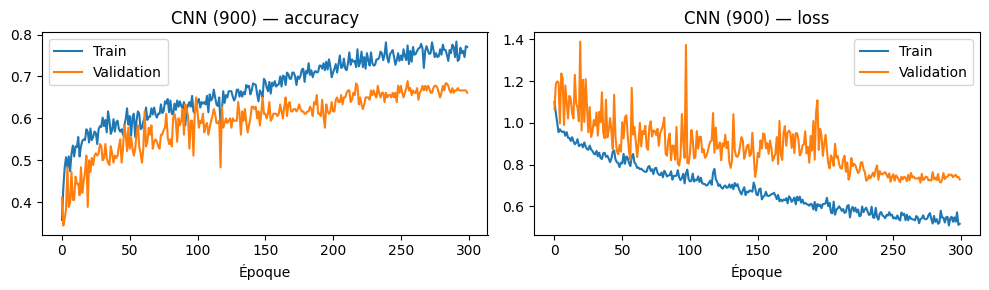

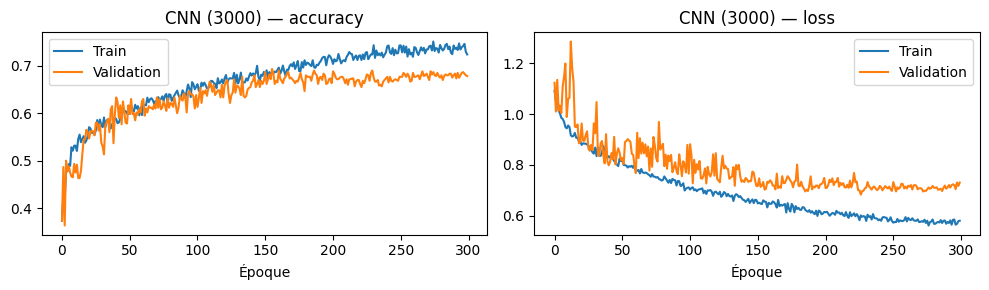

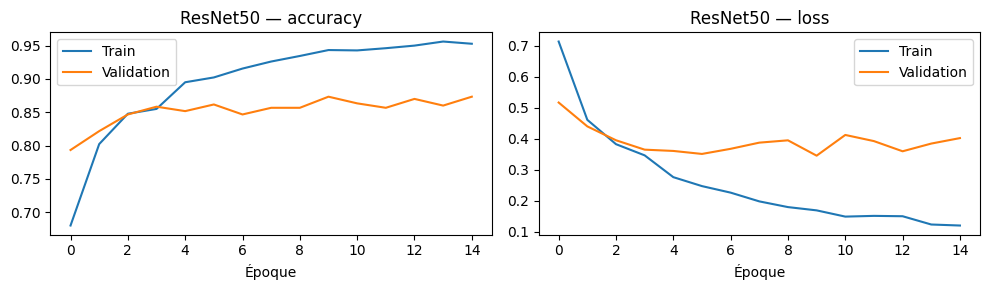

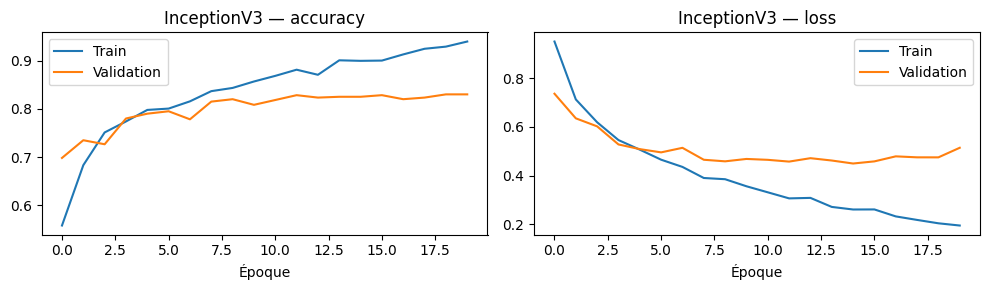

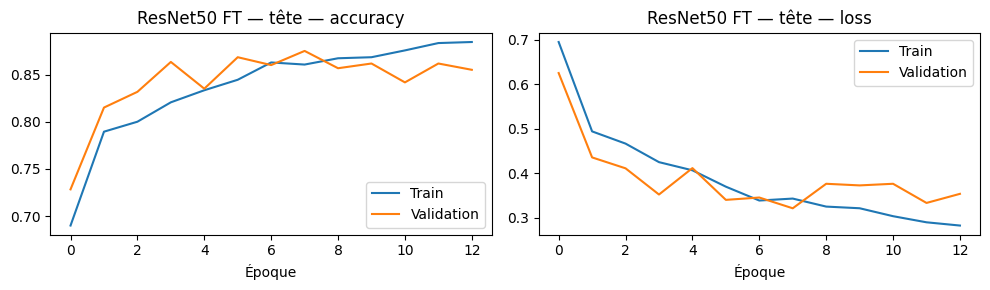

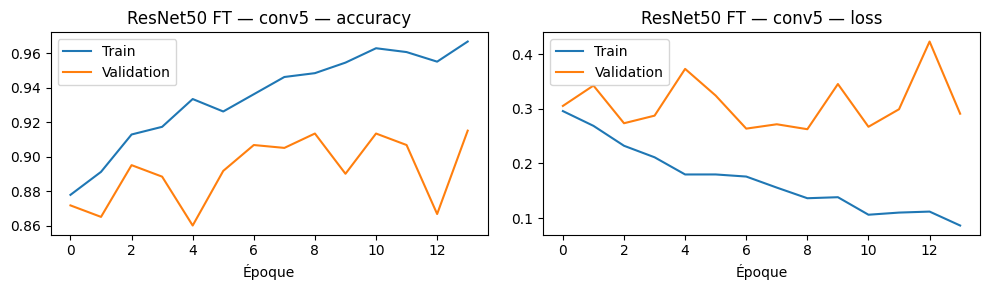

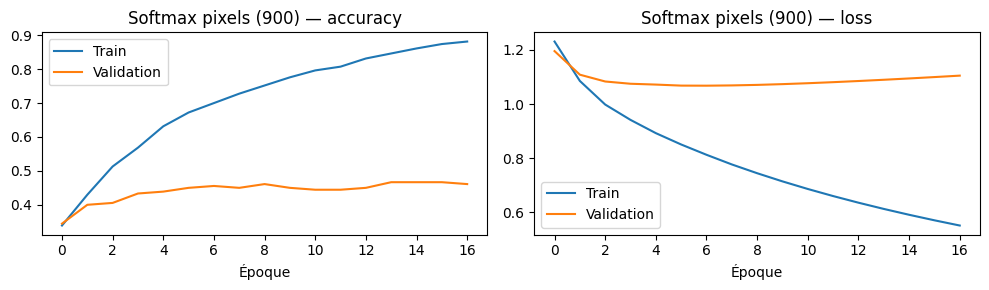

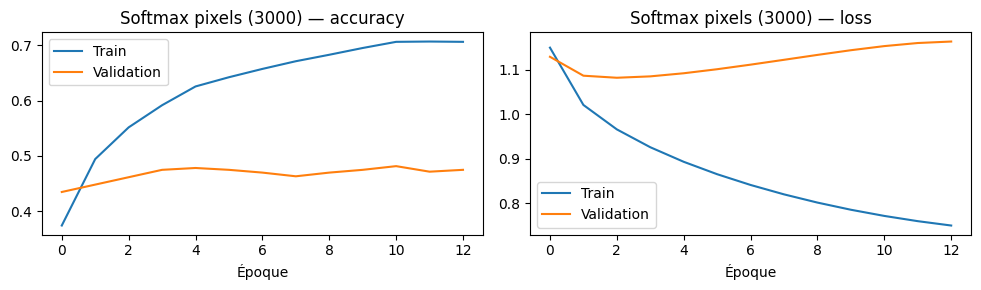

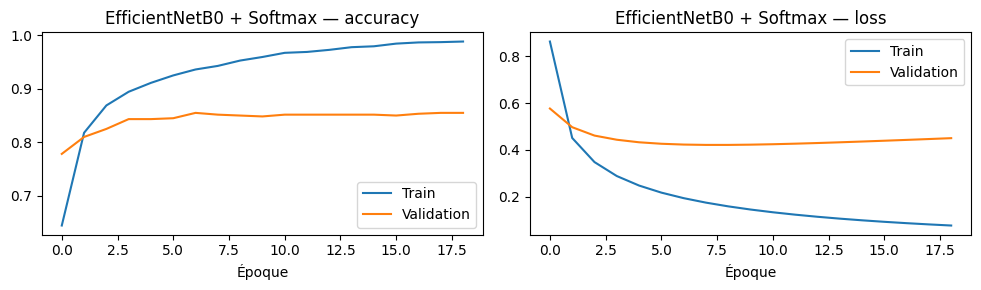

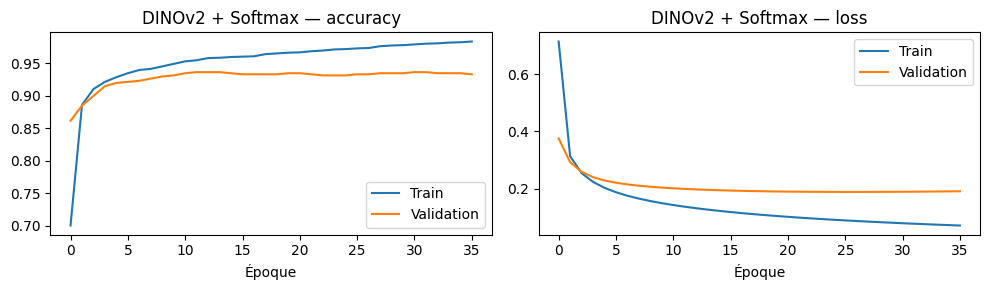

In [18]:
for name, history in histories:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, metric in zip(axes, ['accuracy', 'loss']):
        ax.plot(history[metric], label='Train')
        ax.plot(history['val_' + metric], label='Validation')
        ax.set_title(name + ' — ' + metric)
        ax.set_xlabel('Époque')
        ax.legend()
    plt.tight_layout()
    plt.show()

## 11. Validation et sélection

Les choix de k, distance, checkpoint, TTA et modèle utilisent uniquement la validation. Les labels test ne servent qu’au calcul des scores dans la section suivante.

In [19]:
validation_table = pd.DataFrame(validation_rows, columns=['Modèle', 'Images', 'Taille', 'Validation (%)'])
display(Markdown(validation_table.sort_values(['Images', 'Validation (%)'],
                                              ascending=[True, False]).to_markdown(index=False, floatfmt='.2f')))

# Un candidat retenu par groupe, car les deux groupes ont des tests différents.
selected_models = validation_table.loc[validation_table.groupby('Images')['Validation (%)'].idxmax(),
                                       ['Modèle', 'Images']]
display(Markdown(selected_models.to_markdown(index=False)))

| Modèle                   |   Images |   Taille |   Validation (%) |
|:-------------------------|---------:|---------:|-----------------:|
| CNN (900)                |      900 |       32 |            67.78 |
| Softmax pixels (900)     |      900 |       32 |            45.56 |
| Pixels + KNN             |      900 |       32 |            41.67 |
| DINOv2 + Softmax         |     3000 |      224 |            93.33 |
| DINOv2 + KNN             |     3000 |      224 |            93.00 |
| ResNet50 fine-tuné       |     3000 |      224 |            91.33 |
| ResNet50                 |     3000 |      224 |            87.33 |
| EfficientNetB0 + Softmax |     3000 |      224 |            85.00 |
| EfficientNetB0 + KNN     |     3000 |      224 |            84.00 |
| InceptionV3              |     3000 |      299 |            82.50 |
| CNN (3000) + TTA         |     3000 |       32 |            70.50 |
| Softmax pixels (3000)    |     3000 |       32 |            46.17 |

| Modèle           |   Images |
|:-----------------|---------:|
| CNN (900)        |      900 |
| DINOv2 + Softmax |     3000 |

## 12. Évaluation test

Même ordre des labels et mêmes exemples test pour tous les modèles d’un groupe.

### Pixels + KNN — 180 images test : 41.67%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.39 |     0.45 |       0.42 |     60.00 |
| Lantana      |        0.51 |     0.37 |       0.43 |     60.00 |
| Snake weed   |        0.39 |     0.43 |       0.41 |     60.00 |
| macro avg    |        0.43 |     0.42 |       0.42 |    180.00 |
| weighted avg |        0.43 |     0.42 |       0.42 |    180.00 |

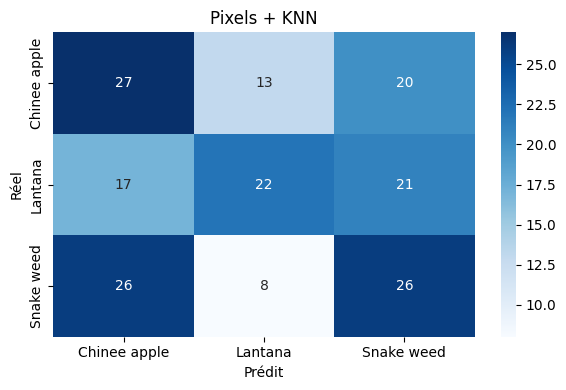

### EfficientNetB0 + KNN — 600 images test : 80.17%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.81 |     0.66 |       0.73 |    200.00 |
| Lantana      |        0.84 |     0.92 |       0.88 |    200.00 |
| Snake weed   |        0.75 |     0.82 |       0.79 |    200.00 |
| macro avg    |        0.80 |     0.80 |       0.80 |    600.00 |
| weighted avg |        0.80 |     0.80 |       0.80 |    600.00 |

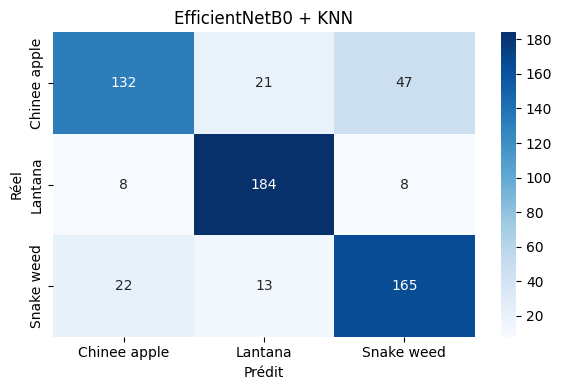

### CNN (900) — 180 images test : 61.11%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.55 |     0.38 |       0.45 |     60.00 |
| Lantana      |        0.73 |     0.78 |       0.76 |     60.00 |
| Snake weed   |        0.54 |     0.67 |       0.60 |     60.00 |
| macro avg    |        0.61 |     0.61 |       0.60 |    180.00 |
| weighted avg |        0.61 |     0.61 |       0.60 |    180.00 |

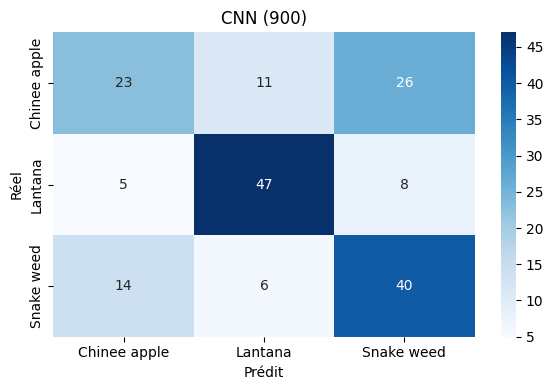

### CNN (3000) + TTA — 600 images test : 70.33%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.62 |     0.63 |       0.62 |    200.00 |
| Lantana      |        0.78 |     0.83 |       0.81 |    200.00 |
| Snake weed   |        0.71 |     0.65 |       0.68 |    200.00 |
| macro avg    |        0.70 |     0.70 |       0.70 |    600.00 |
| weighted avg |        0.70 |     0.70 |       0.70 |    600.00 |

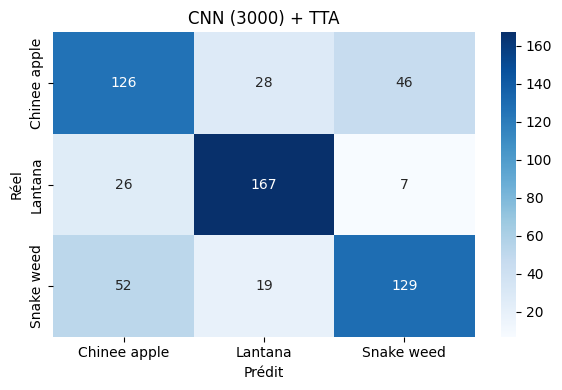

### ResNet50 — 600 images test : 85.67%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.81 |     0.85 |       0.83 |    200.00 |
| Lantana      |        0.92 |     0.91 |       0.91 |    200.00 |
| Snake weed   |        0.84 |     0.81 |       0.83 |    200.00 |
| macro avg    |        0.86 |     0.86 |       0.86 |    600.00 |
| weighted avg |        0.86 |     0.86 |       0.86 |    600.00 |

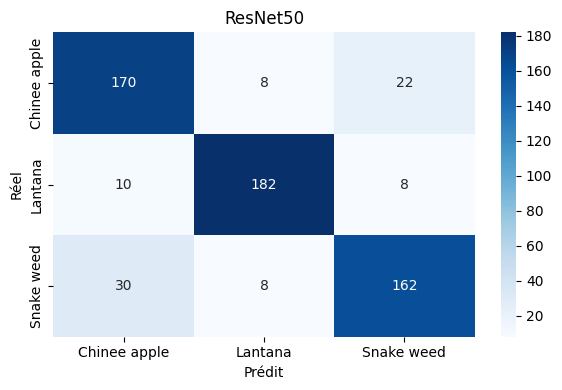

### InceptionV3 — 600 images test : 79.67%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.78 |     0.70 |       0.74 |    200.00 |
| Lantana      |        0.80 |     0.93 |       0.86 |    200.00 |
| Snake weed   |        0.80 |     0.76 |       0.78 |    200.00 |
| macro avg    |        0.80 |     0.80 |       0.79 |    600.00 |
| weighted avg |        0.80 |     0.80 |       0.79 |    600.00 |

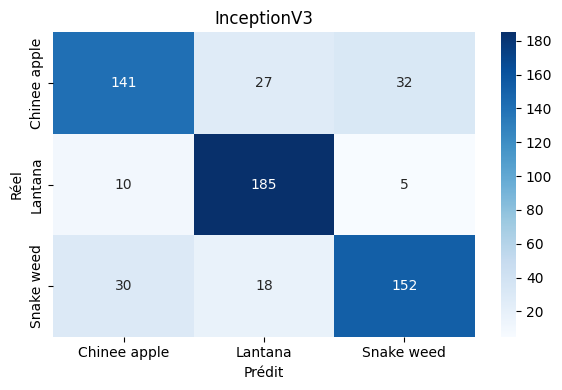

### ResNet50 fine-tuné — 600 images test : 89.17%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.92 |     0.79 |       0.85 |    200.00 |
| Lantana      |        0.93 |     0.97 |       0.95 |    200.00 |
| Snake weed   |        0.83 |     0.92 |       0.87 |    200.00 |
| macro avg    |        0.89 |     0.89 |       0.89 |    600.00 |
| weighted avg |        0.89 |     0.89 |       0.89 |    600.00 |

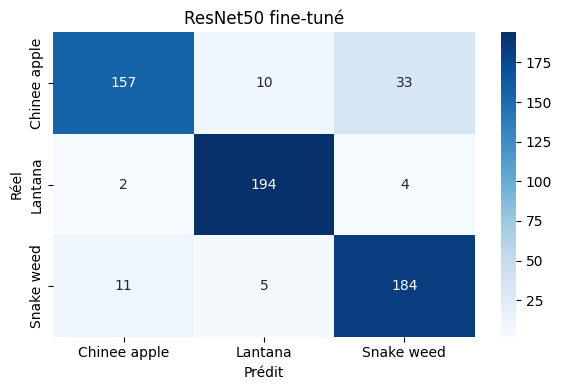

### DINOv2 + KNN — 600 images test : 91.33%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.95 |     0.88 |       0.91 |    200.00 |
| Lantana      |        0.93 |     0.95 |       0.94 |    200.00 |
| Snake weed   |        0.87 |     0.91 |       0.89 |    200.00 |
| macro avg    |        0.91 |     0.91 |       0.91 |    600.00 |
| weighted avg |        0.91 |     0.91 |       0.91 |    600.00 |

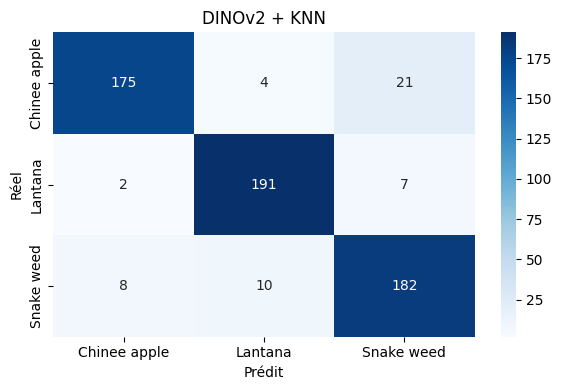

### Softmax pixels (900) — 180 images test : 56.11%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.46 |     0.18 |       0.26 |     60.00 |
| Lantana      |        0.63 |     0.82 |       0.71 |     60.00 |
| Snake weed   |        0.53 |     0.68 |       0.59 |     60.00 |
| macro avg    |        0.54 |     0.56 |       0.52 |    180.00 |
| weighted avg |        0.54 |     0.56 |       0.52 |    180.00 |

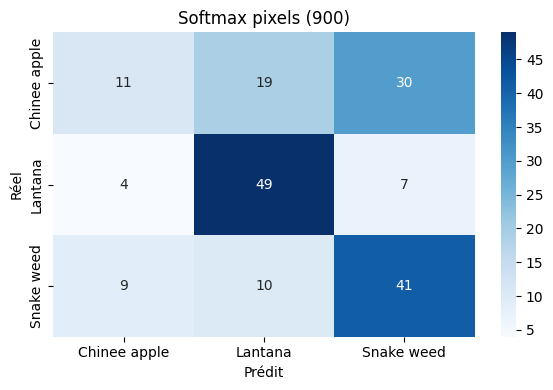

### Softmax pixels (3000) — 600 images test : 45.00%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.38 |     0.57 |       0.46 |    200.00 |
| Lantana      |        0.51 |     0.65 |       0.57 |    200.00 |
| Snake weed   |        0.59 |     0.13 |       0.21 |    200.00 |
| macro avg    |        0.49 |     0.45 |       0.41 |    600.00 |
| weighted avg |        0.49 |     0.45 |       0.41 |    600.00 |

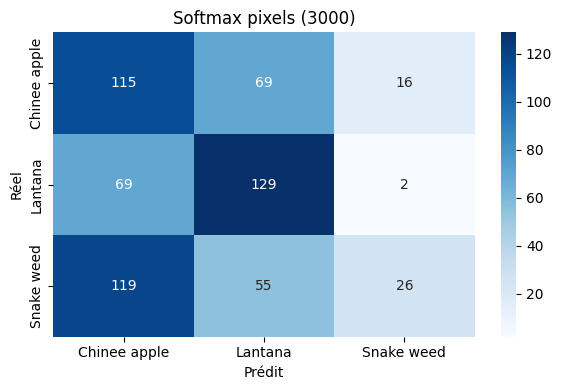

### EfficientNetB0 + Softmax — 600 images test : 85.00%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.83 |     0.77 |       0.80 |    200.00 |
| Lantana      |        0.92 |     0.94 |       0.93 |    200.00 |
| Snake weed   |        0.80 |     0.84 |       0.82 |    200.00 |
| macro avg    |        0.85 |     0.85 |       0.85 |    600.00 |
| weighted avg |        0.85 |     0.85 |       0.85 |    600.00 |

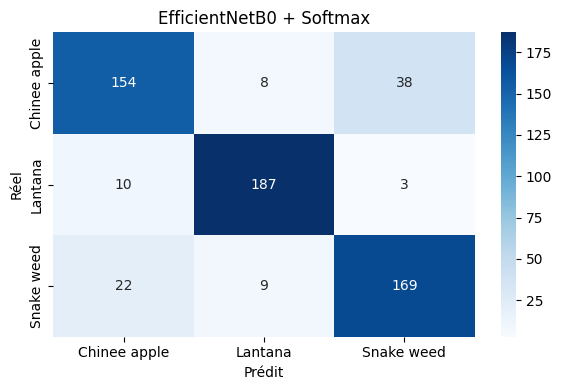

### DINOv2 + Softmax — 600 images test : 91.50%

|              |   precision |   recall |   f1-score |   support |
|:-------------|------------:|---------:|-----------:|----------:|
| Chinee apple |        0.92 |     0.88 |       0.90 |    200.00 |
| Lantana      |        0.95 |     0.94 |       0.95 |    200.00 |
| Snake weed   |        0.88 |     0.93 |       0.90 |    200.00 |
| macro avg    |        0.92 |     0.92 |       0.92 |    600.00 |
| weighted avg |        0.92 |     0.92 |       0.92 |    600.00 |

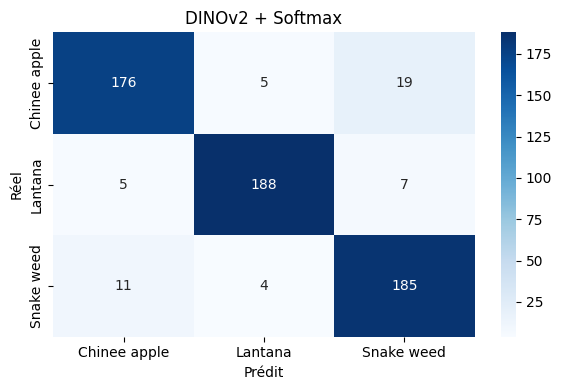

In [20]:
test_rows = []
for name, true_labels, prediction in test_predictions:
    accuracy = accuracy_score(true_labels, prediction) * 100
    macro_f1 = f1_score(true_labels, prediction, average='macro', zero_division=0) * 100
    test_rows.append([name, len(true_labels), accuracy, macro_f1])
    display(Markdown(f'### {name} — {len(true_labels)} images test : {accuracy:.2f}%'))
    report = classification_report(true_labels, prediction, labels=[0, 1, 2],
                                   target_names=class_names, output_dict=True, zero_division=0)
    display(Markdown(pd.DataFrame(report).T.drop('accuracy').to_markdown(floatfmt='.2f')))
    plt.figure(figsize=(6, 4))
    sns.heatmap(confusion_matrix(true_labels, prediction, labels=[0, 1, 2]), annot=True, fmt='d',
                xticklabels=class_names, yticklabels=class_names, cmap='Blues')
    plt.title(name)
    plt.xlabel('Prédit')
    plt.ylabel('Réel')
    plt.tight_layout()
    plt.show()

## 13. Comparaison finale

Tous les scores sont **recalculés**, sans recopier les anciens résultats. CNN (3000) et DINOv2 utilisent le même volume et les mêmes splits ; les préentraînements, résolutions et méthodes restent distincts. Un seul split ne permet pas de conclure qu’une famille d’architectures est toujours supérieure.

In [21]:
test_table = pd.DataFrame(test_rows, columns=['Modèle', 'Images test', 'Test (%)', 'F1 macro (%)'])
comparison = validation_table.merge(test_table, on='Modèle')
comparison = comparison.sort_values(['Images', 'Validation (%)'], ascending=[True, False])
display(Markdown(comparison.to_markdown(index=False, floatfmt='.2f')))

for name in selected_models['Modèle']:
    row = comparison[comparison['Modèle'] == name].iloc[0]
    print(f"Groupe {int(row['Images'])} : {name} | Test : {row['Test (%)']:.2f}% | F1 macro : {row['F1 macro (%)']:.2f}%")

| Modèle                   |   Images |   Taille |   Validation (%) |   Images test |   Test (%) |   F1 macro (%) |
|:-------------------------|---------:|---------:|-----------------:|--------------:|-----------:|---------------:|
| CNN (900)                |      900 |       32 |            67.78 |           180 |      61.11 |          60.20 |
| Softmax pixels (900)     |      900 |       32 |            45.56 |           180 |      56.11 |          52.21 |
| Pixels + KNN             |      900 |       32 |            41.67 |           180 |      41.67 |          41.73 |
| DINOv2 + Softmax         |     3000 |      224 |            93.33 |           600 |      91.50 |          91.51 |
| DINOv2 + KNN             |     3000 |      224 |            93.00 |           600 |      91.33 |          91.34 |
| ResNet50 fine-tuné       |     3000 |      224 |            91.33 |           600 |      89.17 |          89.05 |
| ResNet50                 |     3000 |      224 |            87.33 |           600 |      85.67 |          85.68 |
| EfficientNetB0 + Softmax |     3000 |      224 |            85.00 |           600 |      85.00 |          84.94 |
| EfficientNetB0 + KNN     |     3000 |      224 |            84.00 |           600 |      80.17 |          79.85 |
| InceptionV3              |     3000 |      299 |            82.50 |           600 |      79.67 |          79.40 |
| CNN (3000) + TTA         |     3000 |       32 |            70.50 |           600 |      70.33 |          70.20 |
| Softmax pixels (3000)    |     3000 |       32 |            46.17 |           600 |      45.00 |          41.33 |

Groupe 900 : CNN (900) | Test : 61.11% | F1 macro : 60.20%
Groupe 3000 : DINOv2 + Softmax | Test : 91.50% | F1 macro : 91.51%
